<a href="https://colab.research.google.com/github/ReNZzyi/IT-and-Programming/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 11. Работа с изображениями. Библиотека Pillow

ФИО студента: **Петров Данила Максимович**

Группа студента: **ИНБ-б-о-26-2**

Вариант: **14**

## Задание

Изучите инструментарий библиотеки Pillow. Спроектируйте свой собственный фильтр. Продемонстрируйте его работу и поясните назначение предложенного фильтра.

## Анализ задания, получение данных

**Назначение фильтра.** В информационной безопасности часто нужно опубликовать скриншот или фотографию, скрыв часть информации: лицо человека, номер автомобиля, пароль, токен, QR-код. Для этого спроектируем фильтр **«Мозаика-анонимайзер»** (`MosaicFilter`), который скрывает заданную прямоугольную область изображения.

**Алгоритм.** Область разбивается на квадратные блоки размером `block_size × block_size`. Цвет каждого пикселя блока заменяется средним цветом блока:

$$P'(x, y) = \frac{1}{k^2}\sum_{(i,j) \in блок} P(i, j)$$

Мелкие детали внутри блока исчезают, остаётся только общий цвет. Чем больше блок, тем меньше информации остаётся.

**Реализация средствами Pillow:**
1. `crop(box)` - вырезаем область;
2. `resize(..., Image.Resampling.BOX)` - уменьшаем область в `block_size` раз. Фильтр `BOX` при уменьшении усредняет все пиксели, попавшие в один новый пиксель, - это и есть среднее по блоку;
3. `resize(..., Image.Resampling.NEAREST)` - увеличиваем обратно без сглаживания, каждый пиксель превращается в однотонный квадрат;
4. `paste()` - вставляем результат на место исходной области.

Дополнительно предусмотрим режим `solid` - сплошную заливку области. Зачем он нужен, покажем в эксперименте с текстом.

Выполним загрузку файла

In [ ]:
!wget https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract11/cat.jpeg

Можно скопировать и поместить файл с данными любым удобным способом

Импортируем модули и загрузим изображение в память

Размер: (690, 380) | режим: RGB


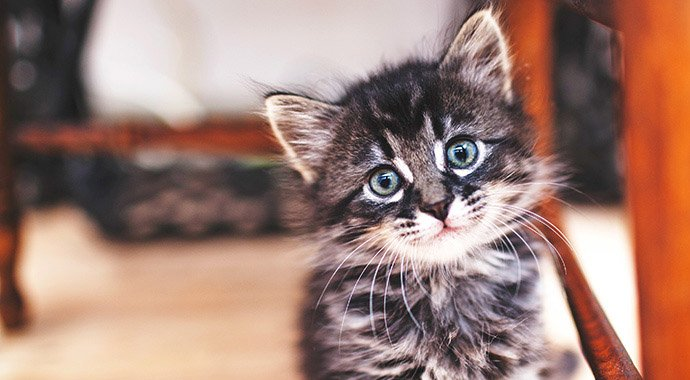

In [2]:
from PIL import Image, ImageDraw, ImageFilter, ImageFont
from matplotlib import pyplot as plt
import numpy as np

with Image.open('cat.jpeg') as img:
    img.load()

print('Размер:', img.size, '| режим:', img.mode)
display(img)

## Объявление фильтра

In [3]:
class MosaicFilter:
    MODES = ('mosaic', 'solid')

    def __init__(self, block_size=16, box=None, mode='mosaic', fill=(0, 0, 0)):
        if block_size < 2:
            raise ValueError('Размер блока должен быть не меньше 2')
        if mode not in self.MODES:
            raise ValueError(f'Режим должен быть одним из {self.MODES}')
        self.block_size = block_size
        self.box = box
        self.mode = mode
        self.fill = fill

    def apply(self, image):
        result = image.convert('RGB')
        box = self.box or (0, 0, result.width, result.height)
        region = result.crop(box)
        width, height = region.size

        if self.mode == 'solid':
            region = Image.new('RGB', region.size, self.fill)
        else:
            small_size = (max(1, width // self.block_size),
                          max(1, height // self.block_size))
            small = region.resize(small_size, Image.Resampling.BOX)
            region = small.resize((width, height), Image.Resampling.NEAREST)

        result.paste(region, box[:2])
        return result

Фильтр оформлен классом: параметры задаются один раз в конструкторе, после чего один и тот же объект фильтра можно применять к любому количеству изображений методом `apply()`. Стандартные фильтры Pillow (`ImageFilter.BLUR` и др.) работают на уровне ядра библиотеки на C, а наш фильтр собран из высокоуровневых операций `crop`, `resize`, `paste`.

Если ширина области не делится на `block_size` нацело, блоки получаются немного разного размера (`resize` распределяет остаток). На результат это практически не влияет.

## Демонстрация работы фильтра

Скроем морду котёнка - так же поступают с лицами людей на фотографиях перед публикацией

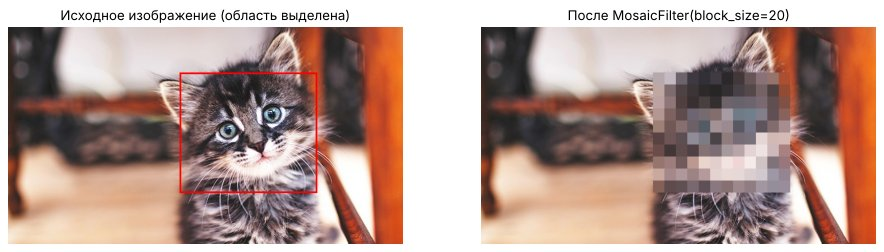

In [4]:
face_box = (300, 80, 540, 290)
anonymizer = MosaicFilter(block_size=20, box=face_box)
cat_anon = anonymizer.apply(img)

img_marked = img.copy()
ImageDraw.Draw(img_marked).rectangle(face_box, outline='red', width=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(img_marked)
axes[0].set_title('Исходное изображение (область выделена)')
axes[1].imshow(cat_anon)
axes[1].set_title('После MosaicFilter(block_size=20)')
for ax in axes:
    ax.axis('off')
plt.show()

Проверим, что фильтр работает как задумано: внутри области число различных цветов резко уменьшилось, а пиксели вне области не изменились

In [5]:
def count_colors(image, box):
    return len(image.crop(box).getcolors(maxcolors=1_000_000))


src = np.array(img)
dst = np.array(cat_anon)
left, top, right, bottom = face_box
outside = np.ones(src.shape[:2], dtype=bool)
outside[top:bottom, left:right] = False

print('Различных цветов в области до фильтра:   ', count_colors(img, face_box))
print('Различных цветов в области после фильтра:', count_colors(cat_anon, face_box))
print('Пиксели вне области не изменились:', np.array_equal(src[outside], dst[outside]))
print('Исходное изображение не изменилось:', np.array_equal(src, np.array(Image.open('cat.jpeg'))))

Различных цветов в области до фильтра:    30875
Различных цветов в области после фильтра: 120
Пиксели вне области не изменились: True
Исходное изображение не изменилось: True


Блок 240×210 / 20 = 12×10 → после фильтра в области остаётся не более 120 цветов (по одному на блок). Исследуем влияние параметра `block_size`:

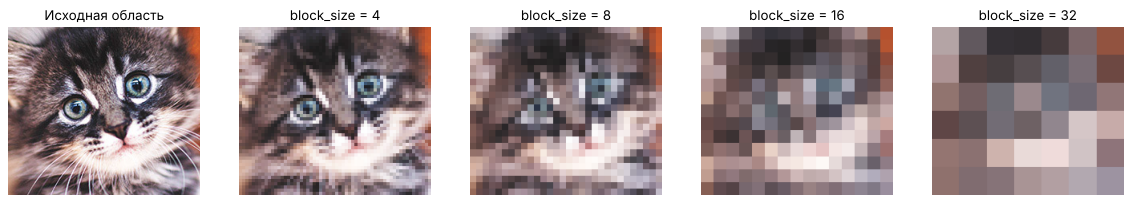

In [6]:
crop_face = img.crop(face_box)
sizes = [4, 8, 16, 32]

fig, axes = plt.subplots(1, len(sizes) + 1, figsize=(18, 3.6))
axes[0].imshow(crop_face)
axes[0].set_title('Исходная область')
for ax, size in zip(axes[1:], sizes):
    ax.imshow(MosaicFilter(block_size=size).apply(crop_face))
    ax.set_title(f'block_size = {size}')
for ax in axes:
    ax.axis('off')
plt.show()

При `block_size = 4` котёнок полностью узнаваем - такое скрытие бесполезно. При 8 детали размыты, но морда читается. При 16 угадываются лишь глаза и общий силуэт, при 32 остаются только цветовые пятна. Размер блока нужно подбирать относительно размера скрываемого объекта: на объект должно приходиться лишь несколько блоков.

## Практический пример: скрытие пароля на скриншоте

Сформируем изображение, имитирующее скриншот с учётными данными (рисуем средствами `ImageDraw`)

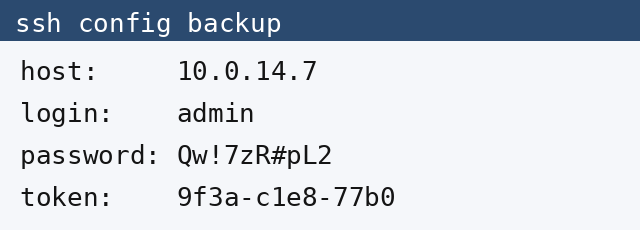

In [7]:
from matplotlib import font_manager

font_path = font_manager.findfont('DejaVu Sans Mono')
font = ImageFont.truetype(font_path, 26)

screen = Image.new('RGB', (640, 230), (245, 247, 250))
draw = ImageDraw.Draw(screen)
draw.rectangle((0, 0, 639, 40), fill=(43, 74, 111))
draw.text((15, 7), 'ssh config backup', font=font, fill='white')
lines = ['host:     10.0.14.7', 'login:    admin', 'password: Qw!7zR#pL2', 'token:    9f3a-c1e8-77b0']
for i, line in enumerate(lines):
    draw.text((20, 55 + i * 42), line, font=font, fill=(20, 20, 20))

secret_box = (175, 135, 560, 220)
screen

Применим фильтр с разными параметрами к области с паролем и токеном

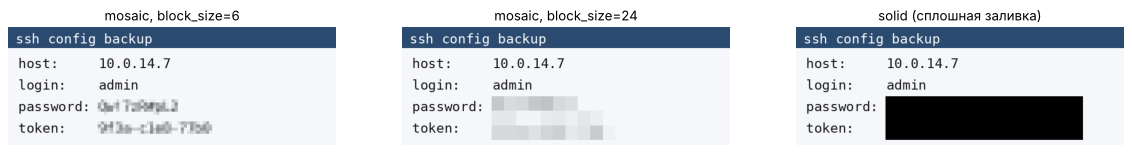

In [8]:
variants = {
    'mosaic, block_size=6': MosaicFilter(6, secret_box),
    'mosaic, block_size=24': MosaicFilter(24, secret_box),
    "solid (сплошная заливка)": MosaicFilter(box=secret_box, mode='solid'),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 3))
for ax, (title, flt) in zip(axes, variants.items()):
    ax.imshow(flt.apply(screen))
    ax.set_title(title)
    ax.axis('off')
plt.show()

**Вывод по эксперименту.** При маленьком блоке символы частично читаются. Даже при крупном блоке мозаика сохраняет усреднённую информацию об исходных пикселях. Для текста, набранного известным шрифтом, такую мозаику можно частично восстановить перебором: существуют инструменты, которые подбирают текст, дающий ту же картинку после пикселизации (например, Depix). Поэтому:
* для лиц и фона мозаика с крупным блоком - приемлемое и визуально аккуратное решение;
* для паролей, ключей и токенов надёжен только режим `solid`: заливка полностью уничтожает исходные пиксели, и восстанавливать нечего.

Важно сохранять результат в новый файл без слоёв (PNG/JPEG). Рисование поверх в редакторах со слоями или в PDF может оставить исходные данные под заливкой.

In [9]:
safe = MosaicFilter(box=secret_box, mode='solid').apply(screen)
safe.save('screenshot_safe.png')
print('Сохранено:', Image.open('screenshot_safe.png').size)

Сохранено: (640, 230)


## Дополнительно: собственное ядро свёртки

Pillow позволяет задать собственное ядро свёртки через `ImageFilter.Kernel`. Спроектируем фильтр **регулируемой резкости** с параметром силы `k`:

$$K = \begin{pmatrix} 0 & -k & 0 \\ -k & 1 + 4k & -k \\ 0 & -k & 0 \end{pmatrix}$$

Центральный пиксель усиливается, соседи вычитаются. На однородных участках изменений нет, а на границах перепад яркости увеличивается. Сумма элементов ядра равна 1, поэтому средняя яркость изображения сохраняется (`scale=1`). При `k = 0` ядро единичное и изображение не меняется.

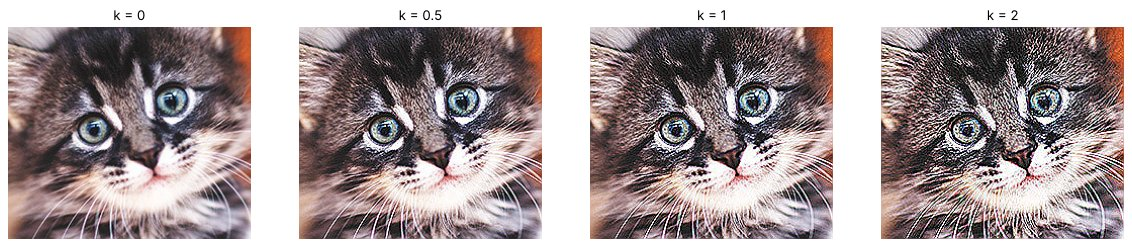

k = 0 не меняет изображение: True


In [10]:
def sharpen_kernel(k):
    return ImageFilter.Kernel(size=(3, 3),
                              kernel=[0, -k, 0,
                                      -k, 1 + 4 * k, -k,
                                      0, -k, 0],
                              scale=1)


strengths = [0, 0.5, 1, 2]
fig, axes = plt.subplots(1, len(strengths), figsize=(18, 4))
for ax, k in zip(axes, strengths):
    ax.imshow(crop_face.filter(sharpen_kernel(k)))
    ax.set_title(f'k = {k}')
    ax.axis('off')
plt.show()

print('k = 0 не меняет изображение:',
      np.array_equal(np.array(crop_face), np.array(crop_face.filter(sharpen_kernel(0)))))

С ростом `k` усиливаются шерсть и усы, но при `k = 2` появляются шум и ореолы на контрастных границах. Разумная сила - 0.5…1.

**Вывод.** Спроектирован и реализован фильтр «Мозаика-анонимайзер» на основе инструментов Pillow (`crop`, `resize` с методами `BOX` и `NEAREST`, `paste`). Он предназначен для скрытия конфиденциальных областей изображения. Эксперименты показали, что надёжность скрытия зависит от размера блока, а для секретного текста нужна сплошная заливка. Дополнительно спроектировано собственное ядро свёртки для регулируемого повышения резкости.

# Контрольные вопросы

**1. Перечислите функции для трансформации изображения: вращение, обрезка и т.д.**

* `crop(box)` - обрезка по прямоугольнику `(left, top, right, bottom)`;
* `resize((w, h), resample)` - изменение размера до заданного;
* `reduce(factor)` - уменьшение в целое число раз;
* `thumbnail((w, h))` - миниатюра с сохранением пропорций (изменяет сам объект);
* `rotate(angle, expand=...)` - поворот на произвольный угол;
* `transpose(method)` - отражения и повороты на 90°: `FLIP_LEFT_RIGHT`, `FLIP_TOP_BOTTOM`, `ROTATE_90`, `ROTATE_180`, `ROTATE_270`, `TRANSPOSE`, `TRANSVERSE`;
* `transform(size, method, data)` - аффинные и перспективные преобразования;
* модуль `ImageOps`: `flip()`, `mirror()`, `fit()`, `pad()`, `expand()`.

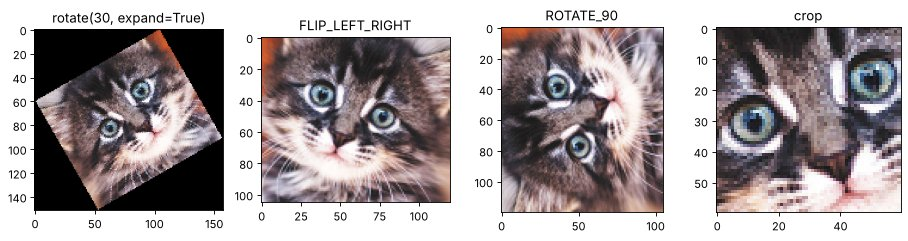

In [11]:
small = crop_face.reduce(2)
results = {
    'rotate(30, expand=True)': small.rotate(30, expand=True),
    'FLIP_LEFT_RIGHT': small.transpose(Image.Transpose.FLIP_LEFT_RIGHT),
    'ROTATE_90': small.transpose(Image.Transpose.ROTATE_90),
    'crop': small.crop((30, 20, 90, 80)),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (title, im) in zip(axes, results.items()):
    ax.imshow(im)
    ax.set_title(title)
plt.show()

**2. Поясните назначение метода `convert()`. Поясните возможные значения параметра данного метода.**

`convert(mode)` возвращает копию изображения в другом цветовом режиме (модели). Основные значения `mode`:
* `'1'` - 1 бит на пиксель, чёрно-белое;
* `'L'` - 8 бит, оттенки серого (яркость считается по формуле `L = 0.299R + 0.587G + 0.114B`);
* `'P'` - 8 бит, индексы в палитре из 256 цветов;
* `'RGB'` - 3×8 бит, полноцветное;
* `'RGBA'` - RGB + канал прозрачности (альфа);
* `'CMYK'` - 4×8 бит, модель для печати;
* `'YCbCr'` - яркость + две цветоразностные компоненты (используется в JPEG и видео);
* `'LAB'`, `'HSV'` - цветовые пространства L\*a\*b и «тон–насыщенность–яркость»;
* `'I'` - 32-битные целые, `'F'` - 32-битные числа с плавающей точкой.

In [12]:
for mode in ['1', 'L', 'P', 'RGB', 'RGBA', 'CMYK', 'YCbCr', 'HSV']:
    converted = img.convert(mode)
    print(f'{mode:>5}: каналы {converted.getbands()}, пиксель (100, 100) = {converted.getpixel((100, 100))}')

    1: каналы ('1',), пиксель (100, 100) = 255
    L: каналы ('L',), пиксель (100, 100) = 177
    P: каналы ('P',), пиксель (100, 100) = 140
  RGB: каналы ('R', 'G', 'B'), пиксель (100, 100) = (187, 173, 173)
 RGBA: каналы ('R', 'G', 'B', 'A'), пиксель (100, 100) = (187, 173, 173, 255)
 CMYK: каналы ('C', 'M', 'Y', 'K'), пиксель (100, 100) = (68, 82, 82, 0)
YCbCr: каналы ('Y', 'Cb', 'Cr'), пиксель (100, 100) = (177, 125, 135)
  HSV: каналы ('H', 'S', 'V'), пиксель (100, 100) = (0, 19, 187)


**3. Что такое фильтрация изображений? Приведите примеры практического применения фильтров.**

Фильтрация - преобразование изображения, при котором новое значение пикселя вычисляется по значениям пикселей в его окрестности. Чаще всего это свёртка с ядром (матрицей весов), как у `ImageFilter.Kernel`. Бывают и нелинейные фильтры (медианный `MedianFilter`, `MinFilter`, `MaxFilter`).

Применение:
* подавление шума - `GaussianBlur`, `MedianFilter` (снимки с камер, сканы документов);
* повышение резкости - `SHARPEN`, `UnsharpMask` (фотография, полиграфия);
* выделение границ - `FIND_EDGES`, `CONTOUR` (компьютерное зрение, распознавание номеров, OCR);
* анонимизация - размытие и мозаика лиц, номеров, персональных данных (как фильтр из этой работы);
* предобработка данных для нейросетей.

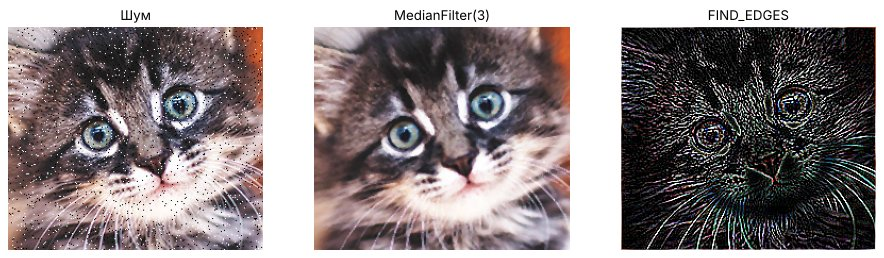

In [13]:
noisy = np.array(crop_face).astype(np.int16)
rng = np.random.default_rng(14)
mask = rng.random(noisy.shape[:2]) < 0.05
noisy[mask] = rng.choice([0, 255], size=(mask.sum(), 1))
noisy = Image.fromarray(noisy.clip(0, 255).astype(np.uint8))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (title, im) in zip(axes, [('Шум', noisy),
                                   ('MedianFilter(3)', noisy.filter(ImageFilter.MedianFilter(3))),
                                   ('FIND_EDGES', crop_face.filter(ImageFilter.FIND_EDGES))]):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis('off')
plt.show()

**4. Поясните формат изображения RGB.**

RGB - аддитивная цветовая модель: любой цвет получается сложением трёх основных - красного (Red), зелёного (Green) и синего (Blue). В режиме `RGB` Pillow каждый пиксель хранит три канала по 8 бит (0…255). Получается 256³ ≈ 16,7 млн цветов. `(0, 0, 0)` - чёрный, `(255, 255, 255)` - белый, `(255, 0, 0)` - чистый красный. Изображение можно разделить на три одноканальных изображения методом `split()`.

In [14]:
r, g, b = img.getpixel((420, 160))
print('Пиксель (420, 160): R =', r, 'G =', g, 'B =', b)
print('Каналы:', [band.mode for band in img.split()], '| форма массива:', np.array(img).shape)

Пиксель (420, 160): R = 109 G = 75 B = 76
Каналы: ['L', 'L', 'L'] | форма массива: (380, 690, 3)


**5. Поясните значение терминов: растр, формат изображения, палитра, глубина, разрешение изображения.**

* **Растр** - представление изображения в виде прямоугольной сетки (матрицы) пикселей, каждый из которых имеет свой цвет. Противоположность - векторная графика, где изображение описано геометрическими примитивами.
* **Формат изображения** - способ хранения изображения в файле: структура заголовка, метод сжатия, поддержка прозрачности и метаданных. Примеры: JPEG (сжатие с потерями), PNG (без потерь, прозрачность), GIF (палитра, анимация), BMP, TIFF, WebP.
* **Палитра** - таблица цветов, на которую ссылаются пиксели. В пикселе хранится не цвет, а номер цвета в палитре (режим `P`). Это экономит память.
* **Глубина цвета** - количество бит на пиксель. Определяет число возможных цветов: 1 бит - 2 цвета, 8 бит - 256, 24 бита (RGB) - ≈16,7 млн.
* **Разрешение** - размер изображения в пикселях (например, 690×380). Для печати также плотность - число точек на дюйм (DPI).

In [15]:
print('Формат:', Image.open('cat.jpeg').format, '| размер:', img.size, '| режим:', img.mode)
pal = img.convert('P', palette=Image.Palette.ADAPTIVE, colors=16)
print('Режим P, цветов в палитре:', len(pal.getpalette()) // 3, '| значение пикселя (индекс):', pal.getpixel((0, 0)))

Формат: JPEG | размер: (690, 380) | режим: RGB
Режим P, цветов в палитре: 16 | значение пикселя (индекс): 15


**6. Опишите возможности библиотеки Pillow. Приведите примеры методов, которые могут модифицировать изображения.**

Pillow - основная библиотека Python для работы с растровыми изображениями. Возможности:
* открытие и сохранение десятков форматов (`Image.open()`, `save()`), чтение метаданных (EXIF);
* создание изображений (`Image.new()`) и рисование (`ImageDraw`: линии, фигуры, текст с `ImageFont`);
* геометрические преобразования: `resize`, `crop`, `rotate`, `transpose`, `thumbnail`;
* работа с цветом и каналами: `convert`, `split`, `merge`, `point`, `getpixel`/`putpixel`;
* фильтрация: `filter()` и модуль `ImageFilter`;
* коррекция: `ImageEnhance` (яркость, контраст, насыщенность, резкость), `ImageOps` (автоконтраст, выравнивание гистограммы, инверсия, `grayscale`);
* композиция: `paste`, `Image.blend`, `Image.composite`, `alpha_composite`;
* обмен с NumPy: `np.array(img)` и `Image.fromarray()`.

Методы, модифицирующие **сам объект**: `paste()`, `putpixel()`, `thumbnail()`, рисование через `ImageDraw`. Большинство остальных (`resize`, `rotate`, `filter`, `convert`) возвращают новое изображение.

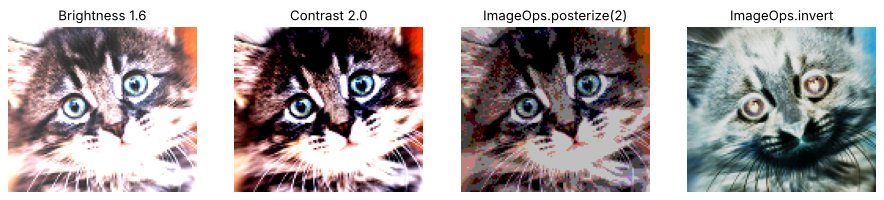

In [16]:
from PIL import ImageEnhance, ImageOps

demo = crop_face.reduce(2)
results = {
    'Brightness 1.6': ImageEnhance.Brightness(demo).enhance(1.6),
    'Contrast 2.0': ImageEnhance.Contrast(demo).enhance(2.0),
    'ImageOps.posterize(2)': ImageOps.posterize(demo, 2),
    'ImageOps.invert': ImageOps.invert(demo),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (title, im) in zip(axes, results.items()):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis('off')
plt.show()